<a href="https://colab.research.google.com/github/Series-Parallel/Machine_in_control/blob/main/cartpole_pid.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ---- Cell 1: cart-pole dynamics (plain NumPy) ----
# State s = [x, x_dot, theta, theta_dot]; theta = 0 is UPRIGHT (unstable), positive = leaning right.
# Input F = horizontal force on the cart (N), positive = push right.
# Lagrangian derivation gives (l = half pole length, point-mass-like pole on a rigid rod):
#   temp      = (F + m*l*th_dot^2*sin(th)) / (M+m)
#   th_ddot   = (g*sin(th) - cos(th)*temp) / (l*(4/3 - m*cos(th)^2/(M+m)))
#   x_ddot    = temp - m*l*th_ddot*cos(th)/(M+m)
import numpy as np
import matplotlib.pyplot as plt

class CartPole:
    def __init__(self, M=1.0, m=0.1, l=0.5, g=9.81, dt=0.005):
        self.M, self.m, self.l, self.g, self.dt = M, m, l, g, dt

    def deriv(self, s, F):
        x, xd, th, thd = s
        M, m, l, g = self.M, self.m, self.l, self.g
        sin, cos = np.sin(th), np.cos(th)
        temp = (F + m * l * thd**2 * sin) / (M + m)
        thdd = (g * sin - cos * temp) / (l * (4/3 - m * cos**2 / (M + m)))
        xdd = temp - m * l * thdd * cos / (M + m)
        return np.array([xd, xdd, thd, thdd])

    def step(self, s, F):
        """One RK4 step (force held constant over dt, like a zero-order-hold controller)."""
        dt = self.dt
        k1 = self.deriv(s, F)
        k2 = self.deriv(s + 0.5*dt*k1, F)
        k3 = self.deriv(s + 0.5*dt*k2, F)
        k4 = self.deriv(s + dt*k3, F)
        return s + dt/6 * (k1 + 2*k2 + 2*k3 + k4)

# Sanity check: with no control, a 0.05 rad tilt must fall over (upright is unstable).
cp = CartPole(); s = np.array([0, 0, 0.05, 0.0])
for _ in range(int(1.0/cp.dt)): s = cp.step(s, 0.0)
print(f"No control, after 1 s: theta = {s[2]:.2f} rad (started at 0.05) -> falls, as expected")

No control, after 1 s: theta = 1.26 rad (started at 0.05) -> falls, as expected


In [ ]:
# ---- Cell 2: PID controller class ----
class PID:
    """PID on the pole angle with:
       - derivative on MEASUREMENT (no 'kick' when the setpoint changes)
       - low-pass filtered derivative (tames sensor noise; tau = filter time constant)
       - anti-windup by clamping the integrator (limits the I term's contribution)
       - output saturation (a real motor cannot push infinitely hard)"""
    def __init__(self, kp, ki, kd, dt, u_max=30.0, i_max=10.0, tau=0.01):
        self.kp, self.ki, self.kd, self.dt = kp, ki, kd, dt
        self.u_max, self.i_max, self.tau = u_max, i_max, tau
        self.reset()

    def reset(self):
        self.i_term, self.prev_meas, self.d_filt = 0.0, None, 0.0

    def __call__(self, meas, setpoint=0.0):
        # Sign: angle is positive when the pole leans right -> push the cart right (same sign),
        # so error = meas - setpoint (direct-acting loop).
        err = meas - setpoint
        self.i_term = np.clip(self.i_term + self.ki * err * self.dt, -self.i_max, self.i_max)
        raw_d = 0.0 if self.prev_meas is None else (meas - self.prev_meas) / self.dt
        a = self.dt / (self.tau + self.dt)
        self.d_filt += a * (raw_d - self.d_filt)
        self.prev_meas = meas
        u = self.kp * err + self.i_term + self.kd * self.d_filt
        return float(np.clip(u, -self.u_max, self.u_max))

In [ ]:
# ---- Cell 3: closed-loop simulation ----
def simulate(pid, th0=0.1, T=5.0, noise_std=0.0, push=None, seed=0, plant=None):
    """push = (time_s, force_N, duration_s) optional disturbance on the cart.
    Returns log with columns: t, x, theta, theta_dot, F, fell."""
    rng = np.random.default_rng(seed)
    cp = plant or CartPole()
    pid.reset()
    s = np.array([0.0, 0.0, th0, 0.0])
    n = int(T / cp.dt)
    log = np.zeros((n, 6))
    fell = False
    for k in range(n):
        t = k * cp.dt
        meas = s[2] + rng.normal(0, noise_std)
        F = pid(meas)
        Fd = F
        if push and push[0] <= t < push[0] + push[2]: Fd += push[1]
        s = cp.step(s, Fd)
        if abs(s[2]) > np.pi/4: fell = True   # > 45 deg: call it fallen
        log[k] = [t, s[0], s[2], s[3], F, fell]
        if fell: log = log[:k+1]; break
    return log

In [ ]:
# ---- Cell 4: performance metrics ----
def metrics(log, tol=0.02):
    t, th, F = log[:, 0], log[:, 2], log[:, 4]
    fell = bool(log[-1, 5])
    outside = np.where(np.abs(th) > tol)[0]
    settle = np.nan if fell else (t[outside[-1]] if len(outside) else 0.0)
    return dict(fell=fell, settling_time_s=settle,
                max_angle_rad=float(np.max(np.abs(th))), effort_rms_N=float(np.sqrt(np.mean(F**2))))

In [ ]:
# ---- Cell 5: baseline run (PID kp=100, ki=1, kd=20, start tilted 0.1 rad) ----
pid = PID(kp=100, ki=1, kd=20, dt=0.005)
log = simulate(pid, th0=0.1)
print(metrics(log))

{'fell': False, 'settling_time_s': np.float64(0.335), 'max_angle_rad': 0.09983779705300057, 'effort_rms_N': 0.7163791805273625}


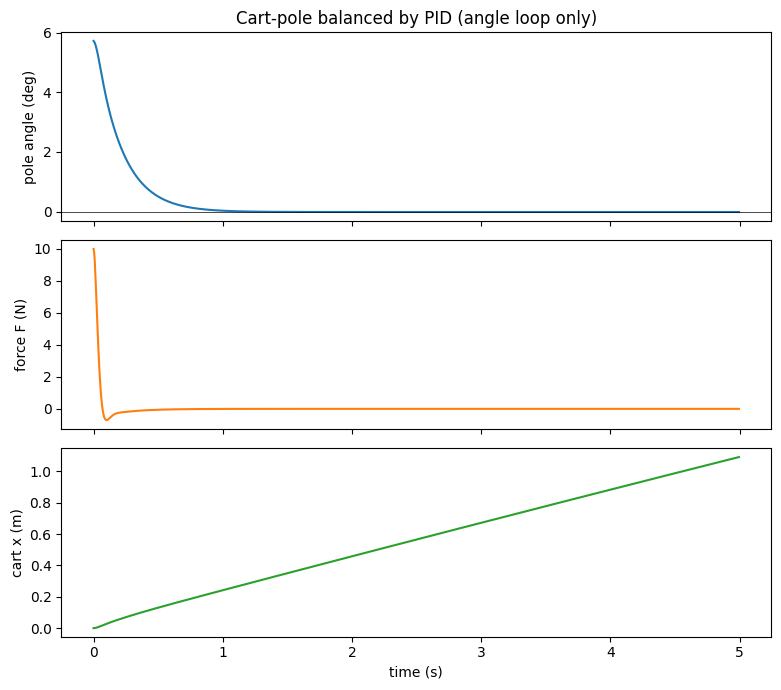

In [ ]:
# ---- Cell 6: response plots for the baseline run ----
fig, ax = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
ax[0].plot(log[:, 0], np.degrees(log[:, 2])); ax[0].set_ylabel("pole angle (deg)"); ax[0].axhline(0, c="k", lw=.5)
ax[1].plot(log[:, 0], log[:, 4], c="C1"); ax[1].set_ylabel("force F (N)")
ax[2].plot(log[:, 0], log[:, 1], c="C2"); ax[2].set_ylabel("cart x (m)"); ax[2].set_xlabel("time (s)")
ax[0].set_title("Cart-pole balanced by PID (angle loop only)")
plt.tight_layout(); plt.show()